In [4]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import plotly.colors as colors

pio.templates.default = "plotly_dark"

In [5]:
data = pd.read_csv("Sample - Superstore.csv", encoding = "latin-1")

In [6]:
data["Order Date"] = pd.to_datetime(data["Order Date"])
data["Order Month"] = data["Order Date"].dt.month
data["Order Year"] = data["Order Date"].dt.year
data["Order DAy of week"] = data["Order Date"].dt.dayofweek


In [81]:
data.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit,Order Month,Order Year,Order DAy of week
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355,2016-05-03 23:06:58.571142,55190.379428,229.858001,3.789574,0.156203,28.656896,7.809686,2015.722233,3.206324
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000,1.000000,2014.000000,0.000000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750,5.000000,2015.000000,1.000000
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500,9.000000,2016.000000,4.000000
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000,11.000000,2017.000000,5.000000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000,12.000000,2017.000000,6.000000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108,3.284654,1.123555,2.122925


Converting Data Columns

In [126]:
data["Ship Date"] = pd.to_datetime(data["Ship Date"])

# Monthly sales analysis

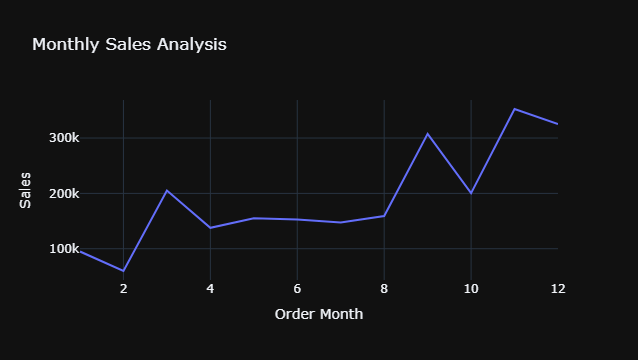

In [10]:
sales_by_month = data.groupby("Order Month")["Sales"].sum().reset_index()
data["Year-Month"] = data["Order Date"].dt.to_period("M")
monthy_sales = data.groupby("Year-Month")['Sales'].sum().reset_index()
monthy_sales['Year-Month'] = monthly_sales["Year-Month"].astype(str)
    
fig = px.line(
    sales_by_month,
    x="Order Month",
    y="Sales",
    title="Monthly Sales Analysis"
)

fig.show()

In [ ]:
# Highest and lowest sales months

In [13]:
highest_sales = monthly_sales.loc[monthly_sales["Sales"].idxmax()]
lowest_sales = monthly_sales.loc[monthly_sales["Sales"].idxmin()]

print("Highest sales month", highest_sales)
print("Lowest sales month", lowest_sales)

Highest sales month Year-Month       2017-11
Sales         118447.825
Name: 46, dtype: object
Lowest sales month Year-Month     2014-02
Sales         4519.892
Name: 1, dtype: object


# Sales by Category

In [9]:
sales_by_category = data.groupby('Category')['Sales'].sum().reset_index()

In [10]:
sales_by_category

,Category,Sales
0,Furniture,741999.7953
1,Office Supplies,719047.0320
2,Technology,836154.0330


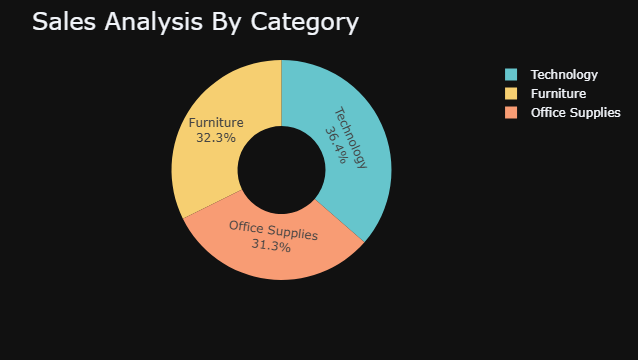

In [18]:
fig = px.pie(sales_by_category,
             values ='Sales',
             names= 'Category',
             hole = 0.4,
             color_discrete_sequence = px.colors.qualitative.Pastel)
fig.update_traces(textposition = "inside", textinfo = "percent+label")
fig.update_layout(title_text = "Sales Analysis By Category", title_font=dict(size=24))
fig.show()

# Sales analysis needs based on sub-category

In [100]:
 sales_by_subcategory = data.groupby("Sub-Category")["Sales"].sum().reset_index()

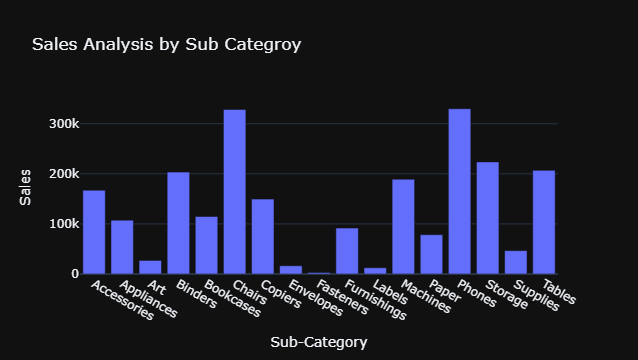

In [101]:
fig = px.bar(sales_by_subcategory, x = "Sub-Category", y = "Sales", title = "Sales Analysis by Sub Categroy")
fig.show()

# Monthly Proft Analysis

In [15]:
profit_by_month = data.groupby('Order Month')['Profit'].sum().reset_index()

monthly_profit = data.groupby("Year-Month")["Profit"].sum().reset_index()
highest_profit = monthly_profit.loc[monthly_profit["Profit"].idxmax()]
print("Highest Profit Month:", highest_profit )

Highest Profit Month: Year-Month       2016-12
Profit        17885.3093
Name: 35, dtype: object


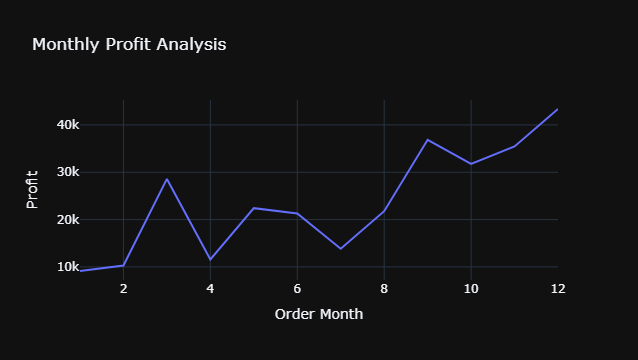

In [16]:
fig = px.line(profit_by_month, x = "Order Month", y = "Profit", title = "Monthly Profit Analysis")
fig.show()

# Profit by category

In [105]:
profit_by_category = data.groupby("Category")["Profit"].sum().reset_index()

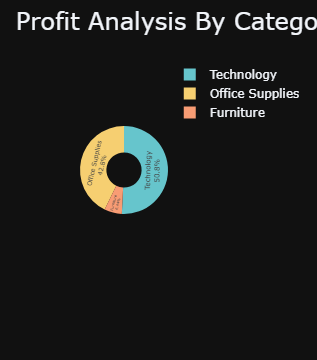

In [115]:
fig = px.pie(profit_by_category,
             values = "Profit",
             names = "Category", 
             hole = 0.4,
             color_discrete_sequence = px.colors.qualitative.Pastel)
fig.update_traces(textposition = "inside", textinfo = "percent+label")
fig.update_layout(title_text = "Profit Analysis By Category", title_font = dict(size = 24))

fig.show()


# Profit Analysis by sub - category

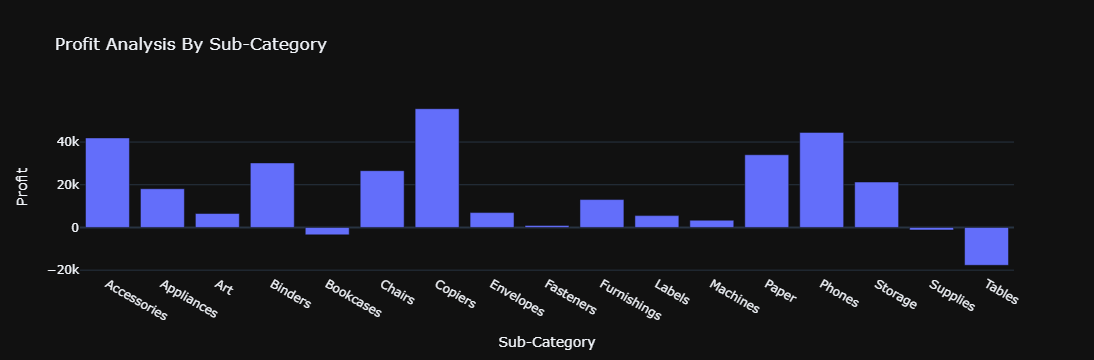

In [117]:
profit_by_subcategory = data.groupby("Sub-Category")["Profit"].sum().reset_index()nm
fig = px.bar(profit_by_subcategory, x = "Sub-Category",
             y = "Profit",
             title= "Profit Analysis By Sub-Category")
fig.show()

# Sales and profit - customer segment

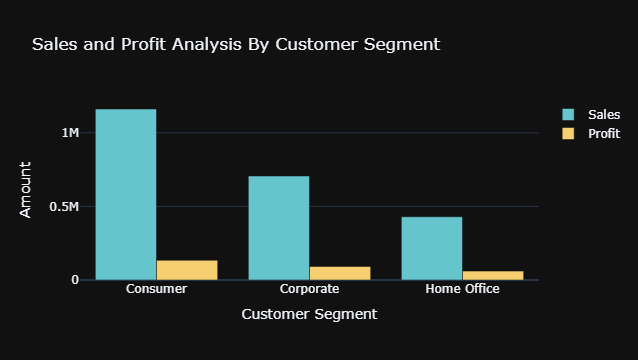

In [119]:
sales_profit_by_segment = data.groupby('Segment').agg({'Sales':'sum', 'Profit': 'sum'}).reset_index()
color_palette = colors.qualitative.Pastel
fig = go.Figure()
fig.add_trace(go.Bar(x = sales_profit_by_segment['Segment'],
                     y = sales_profit_by_segment['Sales'],
                     name = "Sales",
                     marker_color = color_palette[0]))

fig.add_trace(go.Bar(x = sales_profit_by_segment['Segment'],
                     y = sales_profit_by_segment['Profit'],
                     name = "Profit",
                     marker_color = color_palette[1]))
fig.update_layout(title = "Sales and Profit Analysis By Customer Segment",
                  xaxis_title = "Customer Segment", yaxis_title = "Amount")


# Analysis Sales to profit ratio

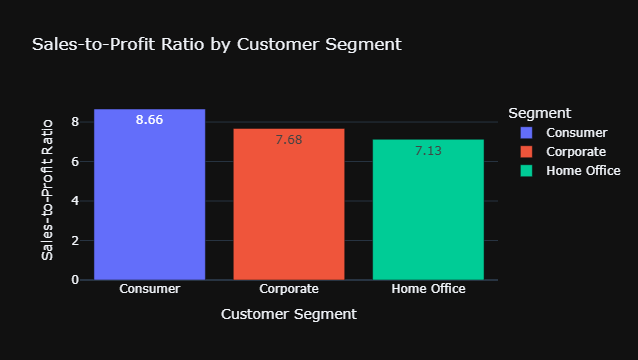

In [31]:
sales_profit_by_segment = data.groupby("Segment").agg({"Sales":"sum", "Profit":"sum"}).reset_index()
sales_profit_by_segment['Sales_to_profit_Ratio'] = sales_profit_by_segment["Sales"]/sales_profit_by_segment["Profit"]

fig = px.bar(
    sales_profit_by_segment,
    x="Segment",
    y="Sales_to_profit_Ratio",
    title="Sales-to-Profit Ratio by Customer Segment",
    color="Segment",
    text_auto=".2f"
)

fig.update_layout(
    xaxis_title="Customer Segment",
    yaxis_title="Sales-to-Profit Ratio",
    template="plotly_dark"
)

fig.show()


# Sales Analysis by State

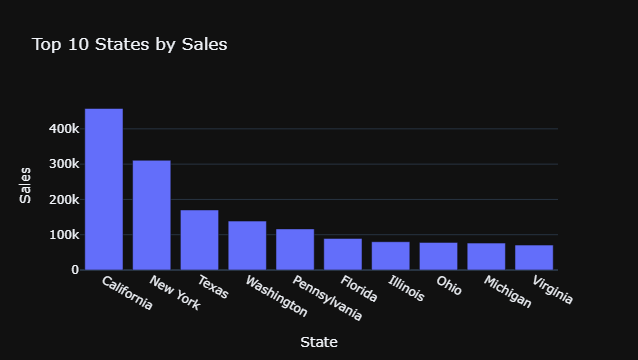

In [22]:
sales_by_state = data.groupby("State")["Sales"].sum().reset_index()
sales_by_state = sales_by_state.sort_values( 
    by="Sales", ascending=False)


fig = px.bar(
    sales_by_state.head(10),
    x="State",
    y="Sales",
    title="Top 10 States by Sales"
)

fig.show()

In [21]:
highest_sales_state = sales_by_state.iloc[0]
print("Highest Sales State:", highest_sales_state)


Highest Sales State: State     California
Sales    457687.6315
Name: 3, dtype: object


# Profit Analysis by Region

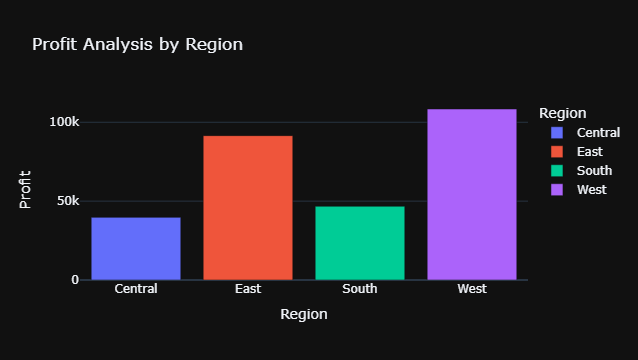

In [25]:
profit_by_region = data.groupby("Region")["Profit"].sum().reset_index()

fig = px.bar(
    profit_by_region,
    x="Region",
    y="Profit",
    title="Profit Analysis by Region",
    color="Region"
)

fig.show() 


# Discount Analysis by Profitability

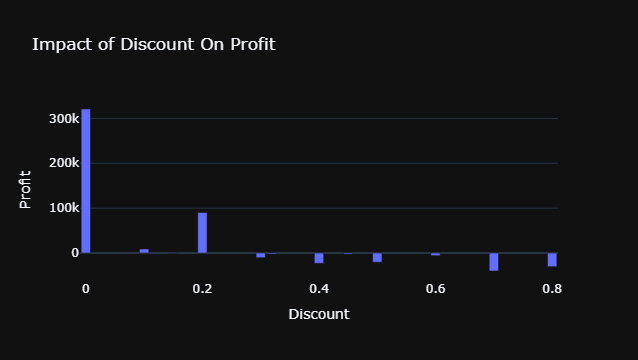

In [28]:
discount_profit = data.groupby("Discount")["Profit"].sum().reset_index()
fig = px.bar(discount_profit, x = "Discount", 
             y = "Profit",
             title = "Impact of Discount On Profit"
            )
fig.show()

# Loss Analysis by Product

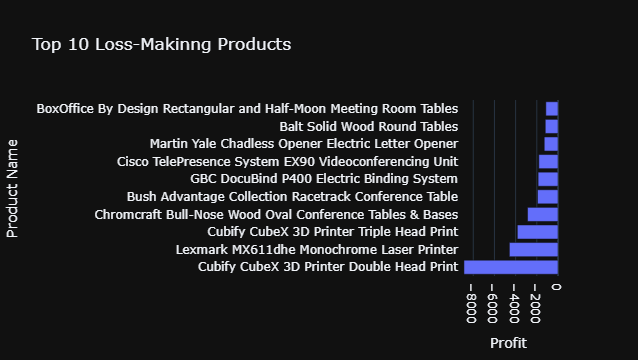

In [29]:
loss_by_product = data.groupby("Product Name")["Profit"].sum().reset_index()
loss_by_product = loss_by_product[loss_by_product["Profit"] < 0]
loss_by_product = loss_by_product.sort_values(
    by="Profit", ascending=True
)
fig = px.bar(
    loss_by_product.head(10),
    x = "Profit",
    y = "Product Name",
    orientation = "h",
    title = "Top 10 Loss-Makinng Products"
)
fig.show()